# Slide 16: how WIDTH and NBASIS_MAX resolve the test KBM's eigenfunction (one figure per code)

Fusion_PhD-qp5.32 (STEP GK talk, 2 Nov 2026). User (2026-11-01): "For three different widths make a plot of the phi and apar fields
with the three different nbasis values used overlayed with different colours ... Only plot the real part ... Let me know what the growth
rate and frequency values are but don't plot it by default."

- Mode: SPR-045 `kbm_free` GS2 sample_0818 (slides 13-15). GS2: the complex final-time re-save `complex_sample_0818/pyroscan.nc`.
- TGLF `fixed_width_f2_sample_0818` (FILTER 2) and GFTM `galF_sample_0818` (FIELD_GALERKIN F = production, FILTER 0.5); both
  `pyroscan.nc` hold complex eigenfunctions. Dominant mode = argmax $\gamma$; a run with no unstable mode is left blank.
- Rows: WIDTH 0.3031 / 0.8 / 1.4, below / inside / above the window where every NBASIS reproduces GS2's $\gamma$ (slide 14).
- Normalisation: every mode (GS2 and code) is divided by $\phi$ at its $|\phi|$ maximum, so $\phi$ is real there and peaks at 1.
- $\gamma$ and $\omega$ of every panel are written to `eigenfunction_resolution_gamma_omega.csv` beside the PNGs, not plotted.


In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# One style for every talk figure (identical in every notebook of this folder; Fusion_PhD-qp5.32). Each PNG fills the right-hand
# ~1060 x 800 px box of a 1920 x 1080 slide, so every figure is 10.6 x 8.0 in at 200 dpi and is saved at exactly that size
# (no bbox_inches="tight"): every PNG is scaled by the same factor on its slide, so text is the same size on every slide.
talk_style = {"figure.figsize": (10.6, 8.0), "savefig.dpi": 200, "savefig.bbox": "standard", "figure.constrained_layout.use": True,
              "font.size": 18, "axes.labelsize": 22, "axes.titlesize": 22, "figure.titlesize": 22,
              "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18, "lines.linewidth": 2.5, "lines.marker": "",
              "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}
plt.rcParams.update(talk_style)
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import pandas as pd
from pyrokinetics import PyroHypercube

single_root = Path(os.environ["GYRO_DATA_OUTPUT"])     # GyroRun wrote the single-mode scans to the scratch tree
leaves = {"TGLF": single_root / "TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_f2_sample_0818",
          "GFTM": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galF_sample_0818"}
code_titles = {"TGLF": "TGLF (FILTER 2)", "GFTM": "GFTM (FILTER 0.5)"}
shown_nbasis = [8, 16, 32]
nbasis_colours = dict(zip(shown_nbasis, plt.cm.viridis(np.linspace(0, 0.9, len(shown_nbasis)))))   # as slides 14, 15, 18, 19
# one WIDTH below, one inside and one above the window where every NBASIS reproduces GS2's gamma (slide 14)
shown_widths = [0.8, 1.4]   # user: 0.3031 and 0.8 look alike; keep the in-window width and the too-wide one
field_labels = {"phi": r"Re $\phi$", "apar": r"Re $A_\parallel$"}


def normalise(eigenfunctions):
    # same convention for every code: rotate so phi is real at its |phi| maximum (pyro's convention), then max|phi| = 1
    phi = eigenfunctions.sel(field="phi")
    return eigenfunctions / phi.isel(theta=int(np.abs(phi).argmax("theta")))


gs2_scan = PyroHypercube.from_directory(single_root / "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_free", pattern="sample_0818", params=["ky"],
                                        gk_code="GS2", file_name="input.in")
gs2_scan.load_gk_output(netcdf_file=single_root / "GS2/Runs/single_mode_spr045/SPR-045/complex_sample_0818/pyroscan.nc")
gs2_output = gs2_scan.gk_output.data.isel(sample=0).pint.dequantify()
gs2_mode = normalise(gs2_output.eigenfunctions.squeeze())
rows = [dict(code="GS2", width=np.nan, nbasis=np.nan, gamma=float(gs2_output.growth_rate), omega=float(gs2_output.mode_frequency))]


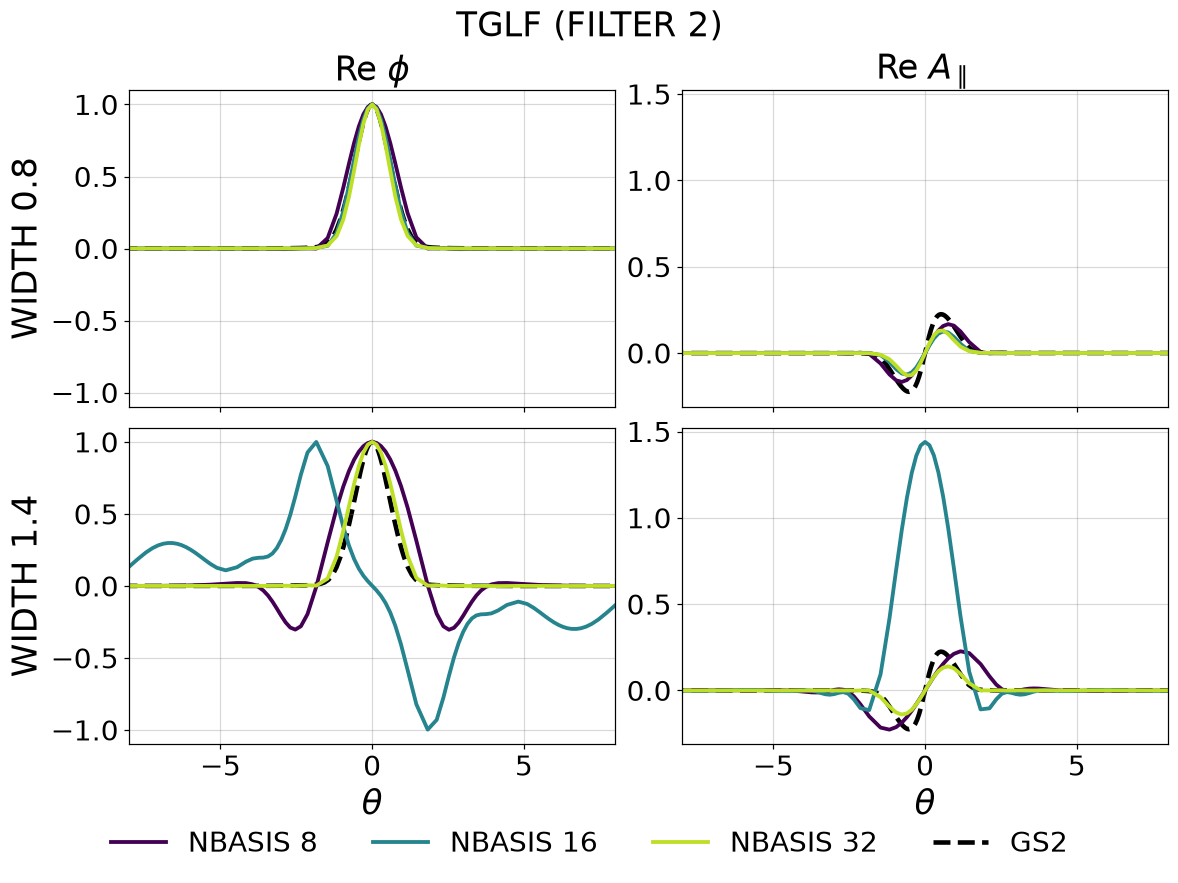

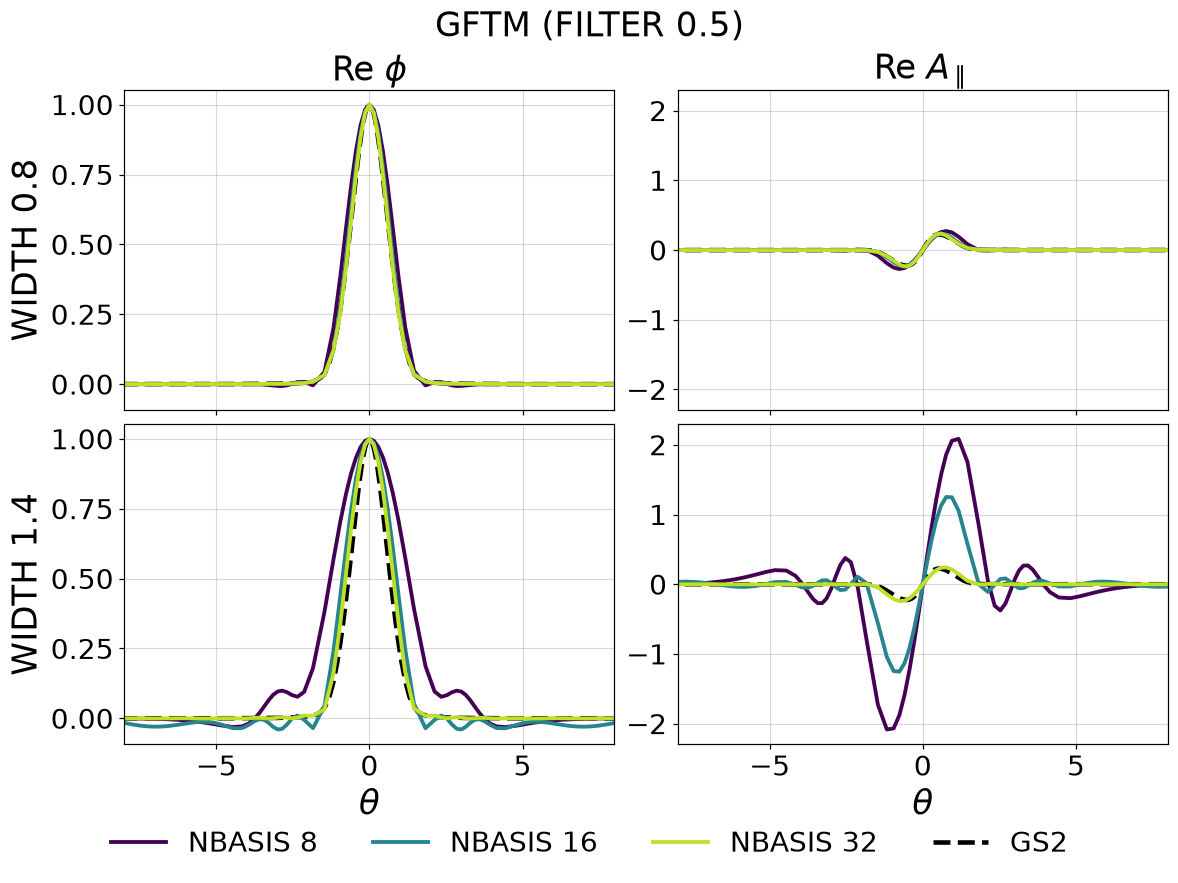

code  width  nbasis    gamma    omega
 GS2    NaN     NaN 1.370788 0.176038
TGLF    0.8     8.0 1.583300 0.072229
TGLF    0.8    16.0 2.616300 0.006420
TGLF    0.8    32.0 2.705200 0.006158
TGLF    1.4     8.0 0.031754 0.006376
TGLF    1.4    16.0 0.059494 0.059904
TGLF    1.4    32.0 2.006300 0.045713
GFTM    0.8     8.0 0.925610 0.246200
GFTM    0.8    16.0 1.305800 0.187810
GFTM    0.8    32.0 1.330100 0.184560
GFTM    1.4     8.0 0.058941 0.012932
GFTM    1.4    16.0 0.176370 0.064211
GFTM    1.4    32.0 1.154000 0.183750


In [2]:
for code, leaf in leaves.items():
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)      # one ky per run
    dominant = output.isel(mode=output.growth_rate.fillna(-np.inf).argmax("mode"))   # dominant mode = argmax growth rate
    fig, axes = plt.subplots(len(shown_widths), 2, figsize=(10.6, 8.0), sharex=True, sharey="col")
    for row, width in enumerate(shown_widths):
        for nbasis in shown_nbasis:
            run = int(np.flatnonzero((np.abs(output.WIDTH.values - width) < 1e-3) & (output.NBASIS_MAX.values == nbasis))[0])
            gamma, omega = float(dominant.growth_rate[run]), float(dominant.mode_frequency[run])
            rows.append(dict(code=code, width=width, nbasis=nbasis, gamma=gamma, omega=omega))
            if gamma > 0:
                mode = normalise(dominant.eigenfunctions.isel(sample=run))
                for ax, field in zip(axes[row], field_labels):
                    ax.plot(mode.theta, mode.sel(field=field).real, color=nbasis_colours[nbasis], label=f"NBASIS {nbasis}")
        for ax, field in zip(axes[row], field_labels):
            ax.plot(gs2_mode.theta, gs2_mode.sel(field=field).real, color="k", lw=3, ls="--", label="GS2", zorder=0)
            ax.set(xlim=(-8, 8))
        axes[row, 0].set_ylabel(f"WIDTH {width:g}")
    for ax, field in zip(axes[0], field_labels):
        ax.set_title(field_labels[field])
    for ax in axes[-1]:
        ax.set_xlabel(r"$\theta$")
    handles, labels = axes[1, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=4)
    fig.suptitle(code_titles[code])
    fig.savefig(plots_dir / f"fig_slide16_{code.lower()}_eigenfunction_resolution.png")
    plt.show()
gamma_omega = pd.DataFrame(rows)
gamma_omega.to_csv(plots_dir / "eigenfunction_resolution_gamma_omega.csv", index=False, float_format="%.4g")
print(gamma_omega.to_string(index=False))
